In [1]:
import math
import random
import copy
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go

# ==============================================================================
# 1. CONSTANTES FÍSICAS Y CONFIGURACIÓN DEL ESCENARIO ASTROSHIELD
# ==============================================================================
EARTH_RADIUS_KM = 6371.0
MAX_EARTH_DIST_KM = math.pi * EARTH_RADIUS_KM

BASE_REGIONS = [
    {"id": "YUC", "name": "Península de Yucatán", "lat": 20.5, "lon": -89.0, "priority": "Alta", "radiusKm": 300.0, "active": True},
    {"id": "AMA", "name": "Amazonía brasileña", "lat": -3.5, "lon": -62.0, "priority": "Alta", "radiusKm": 300.0, "active": True},
    {"id": "CAL", "name": "California, EE. UU.", "lat": 36.8, "lon": -119.4, "priority": "Media", "radiusKm": 300.0, "active": True},
    {"id": "SAH", "name": "Región del Sahel", "lat": 15.0, "lon": 0.0, "priority": "Media", "radiusKm": 300.0, "active": True},
    {"id": "JAP", "name": "Japón", "lat": 36.0, "lon": 138.0, "priority": "Media", "radiusKm": 300.0, "active": True},
    {"id": "AUS", "name": "Interior de Australia", "lat": -25.0, "lon": 133.0, "priority": "Normal", "radiusKm": 300.0, "active": True},
]

BASE_CONSTRAINTS = [
    {"id": "DEB_ATLN", "name": "Atlántico Norte", "kind": "debris", "lat": 45.0, "lon": -35.0, "radiusDeg": 12.0, "active": True},
    {"id": "DEB_PACS", "name": "Pacífico Sur", "kind": "debris", "lat": -30.0, "lon": -120.0, "radiusDeg": 10.0, "active": True},
    {"id": "DEB_POLN", "name": "Región Polar Norte", "kind": "debris", "lat": 78.0, "lon": 30.0, "radiusDeg": 8.0, "active": True},
    {"id": "OBJ_A", "name": "Objeto A", "kind": "occupied", "lat": 10.0, "lon": 45.0, "radiusDeg": 5.0, "active": True},
    {"id": "OBJ_B", "name": "Objeto B", "kind": "occupied", "lat": -15.0, "lon": 110.0, "radiusDeg": 5.0, "active": True},
]

# ==============================================================================
# 2. FUNCIONES GEODÉSICAS SOBRE LA ESFERA (HAVERSINE Y CONTORNOS)
# ==============================================================================
def spherical_distance(lat1, lon1, lat2, lon2):
    """Calcula la distancia ortodrómica en kilómetros y en grados angulares."""
    phi1, lam1 = math.radians(lat1), math.radians(lon1)
    phi2, lam2 = math.radians(lat2), math.radians(lon2)
    dphi = phi2 - phi1
    dlam = lam2 - lam1
    a = math.sin(dphi / 2.0)**2 + math.cos(phi1) * math.cos(phi2) * math.sin(dlam / 2.0)**2
    a = min(1.0, max(0.0, a))
    sigma = 2.0 * math.asin(math.sqrt(a))
    return {
        "km": EARTH_RADIUS_KM * sigma,
        "deg": math.degrees(sigma)
    }

def clamp_satellite(sat):
    """Mantiene las coordenadas dentro del dominio esférico [-90, 90] x [-180, 180]."""
    if sat["lat"] > 90.0:
        sat["lat"] = 180.0 - sat["lat"]
        sat["lon"] += 180.0
    if sat["lat"] < -90.0:
        sat["lat"] = -180.0 - sat["lat"]
        sat["lon"] += 180.0
    sat["lat"] = max(-90.0, min(90.0, sat["lat"]))
    sat["lon"] = ((sat["lon"] + 180.0) % 360.0) - 180.0

def priority_weight(priority):
    if priority == "Alta": return 3.0
    if priority == "Media": return 2.0
    return 1.0

def target_quota(priority):
    return 2 if priority == "Alta" else 1

# ==============================================================================
# 3. FUNCIÓN DE APTITUD (FITNESS) Y DIAGNÓSTICO DE RESTRICCIONES
# ==============================================================================
def evaluate_individual(ind, regions, constraints):
    sats = ind["satellites"]
    active_regions = [r for r in regions if r["active"]]
    active_constraints = [c for c in constraints if c["active"]]

    violations = []
    penalty_score = 0.0

    # 3.1. Verificar zonas restringidas por desechos y posiciones ocupadas
    for sat in sats:
        for c in active_constraints:
            d = spherical_distance(sat["lat"], sat["lon"], c["lat"], c["lon"])
            if d["deg"] <= c["radiusDeg"]:
                depth = c["radiusDeg"] - d["deg"]
                penalty_score += 500.0 + 60.0 * depth
                violations.append({
                    "satId": sat["id"],
                    "constraint": c["name"],
                    "text": f"Sat #{sat['id']} invade {c['name']} ({d['deg']:.2f}° <= {c['radiusDeg']}°)"
                })

    # 3.2. Verificar separación mínima de seguridad entre satélites (50 km)
    for i in range(len(sats)):
        for j in range(i + 1, len(sats)):
            d = spherical_distance(sats[i]["lat"], sats[i]["lon"], sats[j]["lat"], sats[j]["lon"])
            if d["km"] < 50.0:
                penalty_score += 500.0 + 10.0 * (50.0 - d["km"])
                violations.append({
                    "satId": sats[i]["id"],
                    "constraint": "Colisión interna",
                    "text": f"Sat #{sats[i]['id']} y Sat #{sats[j]['id']} a {d['km']:.1f} km (< 50 km)"
                })

    # 3.3. Evaluar cobertura efectiva por región y cuotas de redundancia
    used_sats = set()
    sat_assignments = {s["id"]: "Respaldo / Tránsito" for s in sats}
    sorted_regions = sorted(active_regions, key=lambda r: priority_weight(r["priority"]), reverse=True)

    region_details = {}
    coverage_score = 0.0
    covered_count = 0
    high_redundant_count = 0
    assigned_dists = []

    for reg in sorted_regions:
        w = priority_weight(reg["priority"])
        quota = target_quota(reg["priority"])
        candidates = []

        for sat in sats:
            if sat["id"] in used_sats:
                continue
            d = spherical_distance(sat["lat"], sat["lon"], reg["lat"], reg["lon"])
            if d["km"] <= reg["radiusKm"]:
                candidates.append({"satId": sat["id"], "km": d["km"]})

        candidates.sort(key=lambda x: x["km"])
        effective = candidates[:quota]

        r_score = 0.0
        for idx, c_sat in enumerate(effective):
            bonus = 1.0 + 0.20 * (1.0 - c_sat["km"] / reg["radiusKm"])
            r_score += (100.0 if idx == 0 else 50.0) * w * bonus
            used_sats.add(c_sat["satId"])
            sat_assignments[c_sat["satId"]] = reg["name"]
            assigned_dists.append(c_sat["km"])

        if len(effective) >= 1:
            covered_count += 1
        if reg["priority"] == "Alta" and len(effective) >= 2:
            high_redundant_count += 1
        coverage_score += r_score

        region_details[reg["id"]] = {
            "id": reg["id"],
            "name": reg["name"],
            "priority": reg["priority"],
            "quota": quota,
            "effectiveSats": [e["satId"] for e in effective],
            "minDistKm": effective[0]["km"] if effective else None,
            "isCovered": len(effective) >= 1,
            "quotaMet": len(effective) >= quota
        }

    # 3.4. Gradiente guía continuo hacia regiones con cupos pendientes
    guide_score = 0.0
    avail_free = [s for s in sats if s["id"] not in used_sats]

    for reg in sorted_regions:
        det = region_details[reg["id"]]
        needed = max(0, det["quota"] - len(det["effectiveSats"]))
        w = priority_weight(reg["priority"])

        for _ in range(needed):
            if not avail_free:
                break
            best_idx, best_dist = -1, float("inf")
            for idx, s in enumerate(avail_free):
                d_km = spherical_distance(s["lat"], s["lon"], reg["lat"], reg["lon"])["km"]
                if d_km < best_dist:
                    best_dist = d_km
                    best_idx = idx
            if best_idx >= 0:
                avail_free.pop(best_idx)
                prox = 1.0 - min(best_dist, MAX_EARTH_DIST_KM) / MAX_EARTH_DIST_KM
                guide_score += 15.0 * w * (prox ** 2)
                if det["minDistKm"] is None:
                    det["minDistKm"] = best_dist

    avg_dist = sum(assigned_dists) / len(assigned_dists) if assigned_dists else 0.0
    high_total = sum(1 for r in active_regions if r["priority"] == "Alta")

    ind["report"] = {
        "fitness": coverage_score + guide_score - penalty_score,
        "coverageScore": coverage_score,
        "guideScore": guide_score,
        "penaltyScore": penalty_score,
        "isValid": len(violations) == 0,
        "coveredCount": covered_count,
        "totalRegions": len(active_regions),
        "highRedundantCount": high_redundant_count,
        "highTotal": high_total,
        "avgDistKm": avg_dist,
        "regionDetails": region_details,
        "violations": violations,
        "satAssignments": sat_assignments
    }
    return ind["report"]

# ==============================================================================
# 4. OPERADORES DEL ALGORITMO EVOLUTIVO (RCGA ESFÉRICO)
# ==============================================================================
def create_random_individual(regions, constraints):
    """Inicialización esférica uniforme sin sesgo polar."""
    satellites = []
    for i in range(1, 9):
        u = random.random()
        lat = math.degrees(math.asin(2.0 * u - 1.0))
        lon = random.uniform(-180.0, 180.0)
        satellites.append({"id": i, "lat": lat, "lon": lon})
    ind = {"satellites": satellites}
    evaluate_individual(ind, regions, constraints)
    return ind

def is_better(a, b):
    """Reglas de factibilidad de Deb: válido domina a inválido."""
    if a["report"]["isValid"] and not b["report"]["isValid"]:
        return True
    if not a["report"]["isValid"] and b["report"]["isValid"]:
        return False
    return a["report"]["fitness"] > b["report"]["fitness"]

def tournament_select(pop, k):
    best = random.choice(pop)
    for _ in range(1, k):
        cand = random.choice(pop)
        if is_better(cand, best):
            best = cand
    return best

def crossover_pair(p1, p2, pc):
    """Cruza híbrida con alineación espacial de satélites y soporte de antimeridiano."""
    if random.random() > pc:
        return copy.deepcopy(p1), copy.deepcopy(p2)

    p2_avail = copy.deepcopy(p2["satellites"])
    p2_aligned = []
    for s1 in p1["satellites"]:
        best_idx = min(
            range(len(p2_avail)),
            key=lambda idx: spherical_distance(s1["lat"], s1["lon"], p2_avail[idx]["lat"], p2_avail[idx]["lon"])["km"]
        )
        p2_aligned.append(p2_avail.pop(best_idx))

    c1, c2 = [], []
    for i in range(8):
        s1 = p1["satellites"][i]
        s2 = p2_aligned[i]
        if random.random() < 0.65:
            if random.random() < 0.5:
                c1.append({"id": i + 1, "lat": s1["lat"], "lon": s1["lon"]})
                c2.append({"id": i + 1, "lat": s2["lat"], "lon": s2["lon"]})
            else:
                c1.append({"id": i + 1, "lat": s2["lat"], "lon": s2["lon"]})
                c2.append({"id": i + 1, "lat": s1["lat"], "lon": s1["lon"]})
        else:
            w = random.uniform(0.2, 0.8)
            # Diferencia angular más corta para longitud (antimeridiano)
            dlon = ((s2["lon"] - s1["lon"] + 540.0) % 360.0) - 180.0
            sA = {"id": i + 1, "lat": s1["lat"] * w + s2["lat"] * (1.0 - w), "lon": s1["lon"] + (1.0 - w) * dlon}
            sB = {"id": i + 1, "lat": s2["lat"] * w + s1["lat"] * (1.0 - w), "lon": s1["lon"] + w * dlon}
            clamp_satellite(sA)
            clamp_satellite(sB)
            c1.append(sA)
            c2.append(sB)

    return {"satellites": c1}, {"satellites": c2}

def mutate_individual(ind, gen, max_gen, pm, sigma_start=14.0, sigma_end=0.20):
    """Mutación multiescala: gaussiana fina adaptativa + salto medio + reubicación global."""
    progress = min(1.0, gen / max(1, max_gen))
    sigma = sigma_start * ((sigma_end / sigma_start) ** progress)

    for sat in ind["satellites"]:
        if random.random() < pm:
            r = random.random()
            if r < 0.65:
                sat["lat"] += random.gauss(0.0, sigma)
                sat["lon"] += random.gauss(0.0, sigma)
                clamp_satellite(sat)
            elif r < 0.88:
                jump_scale = 20.0 * (1.0 - 0.65 * progress)
                sat["lat"] += random.gauss(0.0, jump_scale)
                sat["lon"] += random.gauss(0.0, jump_scale)
                clamp_satellite(sat)
            else:
                u = random.random()
                sat["lat"] = math.degrees(math.asin(2.0 * u - 1.0))
                sat["lon"] = random.uniform(-180.0, 180.0)

# ==============================================================================
# 5. EJECUTOR DEL PROCESO EVOLUTIVO (CON SOPORTE WARM-START)
# ==============================================================================
def run_evolution(
    regions,
    constraints,
    pop_size=120,
    max_generations=250,
    tournament_k=4,
    elitism=4,
    pc=0.85,
    pm=0.20,
    seed=42,
    initial_population=None,
    sigma_start=14.0
):
    if seed is not None:
        random.seed(seed)
        np.random.seed(seed)

    if initial_population is None:
        population = [create_random_individual(regions, constraints) for _ in range(pop_size)]
    else:
        # Re-optimización en caliente (Warm-Start): 50% población previa + 50% inmigrantes
        half = pop_size // 2
        kept = copy.deepcopy(initial_population[:half])
        for ind in kept:
            evaluate_individual(ind, regions, constraints)
        immigrants = [create_random_individual(regions, constraints) for _ in range(pop_size - len(kept))]
        population = kept + immigrants

    population.sort(key=lambda ind: (not ind["report"]["isValid"], -ind["report"]["fitness"]))
    best_ind = copy.deepcopy(population[0])

    history = [{
        "gen": 0,
        "bestFitness": best_ind["report"]["fitness"],
        "avgFitness": sum(i["report"]["fitness"] for i in population) / len(population),
        "coveredRegions": best_ind["report"]["coveredCount"],
        "isValid": best_ind["report"]["isValid"]
    }]

    for gen in range(1, max_generations + 1):
        next_pop = [copy.deepcopy(ind) for ind in population[:elitism]]

        while len(next_pop) < pop_size:
            p1 = tournament_select(population, tournament_k)
            p2 = tournament_select(population, tournament_k)
            c1, c2 = crossover_pair(p1, p2, pc)

            mutate_individual(c1, gen, max_generations, pm, sigma_start=sigma_start)
            evaluate_individual(c1, regions, constraints)
            next_pop.append(c1)

            if len(next_pop) < pop_size:
                mutate_individual(c2, gen, max_generations, pm, sigma_start=sigma_start)
                evaluate_individual(c2, regions, constraints)
                next_pop.append(c2)

        population = next_pop
        population.sort(key=lambda ind: (not ind["report"]["isValid"], -ind["report"]["fitness"]))
        if is_better(population[0], best_ind):
            best_ind = copy.deepcopy(population[0])

        history.append({
            "gen": gen,
            "bestFitness": best_ind["report"]["fitness"],
            "avgFitness": sum(i["report"]["fitness"] for i in population) / len(population),
            "coveredRegions": best_ind["report"]["coveredCount"],
            "isValid": best_ind["report"]["isValid"]
        })

    return best_ind, history, population

print("✅ Motor evolutivo AstroShield cargado correctamente.")

✅ Motor evolutivo AstroShield cargado correctamente.


In [2]:
def compute_geodesic_circle(lat, lon, radius_deg, n_points=50):
    """Genera los puntos (lat, lon) de un círculo esférico sobre la Tierra."""
    phi1 = math.radians(lat)
    lam1 = math.radians(lon)
    delta = math.radians(radius_deg)
    lats, lons = [], []
    for i in range(n_points + 1):
        brng = 2.0 * math.pi * i / n_points
        sin_phi2 = math.sin(phi1) * math.cos(delta) + math.cos(phi1) * math.sin(delta) * math.cos(brng)
        phi2 = math.asin(max(-1.0, min(1.0, sin_phi2)))
        y = math.sin(brng) * math.sin(delta) * math.cos(phi1)
        x = math.cos(delta) - math.sin(phi1) * math.sin(phi2)
        lam2 = lam1 + math.atan2(y, x)
        lats.append(math.degrees(phi2))
        lons.append(((math.degrees(lam2) + 540.0) % 360.0) - 180.0)
    return lats, lons

def print_solution_summary(title, best_ind):
    rep = best_ind["report"]
    print("=" * 85)
    print(f"🛰️ {title}")
    print("=" * 85)
    estado_str = "VÁLIDA (0 infracciones)" if rep["isValid"] else f"INVÁLIDA ({len(rep['violations'])} infracciones)"
    print(f"• Estado de Factibilidad : {estado_str}")
    print(f"• Fitness Total          : {rep['fitness']:.2f} (Cobertura: {rep['coverageScore']:.2f} | Guía: {rep['guideScore']:.2f} | Penalización: -{rep['penaltyScore']:.2f})")
    print(f"• Regiones Cubiertas     : {rep['coveredCount']} / {rep['totalRegions']}")
    print(f"• Redundancia P. Alta    : {rep['highRedundantCount']} / {rep['highTotal']}")
    print(f"• Distancia Media Centro : {rep['avgDistKm']:.2f} km")

    if rep["violations"]:
        print("\n⚠️ Infracciones detectadas:")
        for v in rep["violations"]:
            print(f"   - {v['text']}")

    # Tabla de Regiones
    reg_rows = []
    for d in rep["regionDetails"].values():
        reg_rows.append({
            "Región": d["name"],
            "Prioridad": d["priority"],
            "Satélites Asignados": f"{len(d['effectiveSats'])}/{d['quota']} {d['effectiveSats']}",
            "Dist. Mínima (km)": f"{d['minDistKm']:.1f}" if d["minDistKm"] is not None else "N/A",
            "Estado": "ÓPTIMA" if d["quotaMet"] else ("PARCIAL" if d["isCovered"] else "DESCUBIERTA")
        })
    print("\n📊 Estado de Cobertura por Región:")
    display(pd.DataFrame(reg_rows))

    # Tabla de Satélites
    sat_rows = []
    for s in best_ind["satellites"]:
        sat_rows.append({
            "Satélite": f"Sat #{s['id']}",
            "Latitud (°)": round(s["lat"], 4),
            "Longitud (°)": round(s["lon"], 4),
            "Asignación (<= 300 km)": rep["satAssignments"][s["id"]]
        })
    print("\n🛰️ Coordenadas Finales de los 8 Satélites:")
    display(pd.DataFrame(sat_rows))

def plot_convergence_curve(history, title="Curva de Convergencia Evolutiva"):
    gens = [h["gen"] for h in history]
    best_f = [h["bestFitness"] for h in history]
    avg_f = [h["avgFitness"] for h in history]

    plt.figure(figsize=(9, 4), dpi=110)
    plt.plot(gens, best_f, label="Mejor Fitness (Elitismo)", color="#0284c7", linewidth=2.3)
    plt.plot(gens, avg_f, label="Fitness Promedio Población", color="#6366f1", linestyle="--", linewidth=1.5)
    plt.title(title, fontsize=12, fontweight="bold")
    plt.xlabel("Generación")
    plt.ylabel("Aptitud F(C)")
    plt.grid(True, alpha=0.25)
    plt.legend()
    plt.tight_layout()
    plt.show()

def plot_interactive_3d_globe(best_ind, regions, constraints, title="Globo 3D AstroShield"):
    fig = go.Figure()

    # 1. Zonas restringidas y posiciones ocupadas
    for c in constraints:
        if not c["active"]:
            continue
        lats, lons = compute_geodesic_circle(c["lat"], c["lon"], c["radiusDeg"])
        color = "#ef4444" if c["kind"] == "debris" else "#f97316"
        fig.add_trace(go.Scattergeo(
            lat=lats, lon=lons, mode="lines",
            line=dict(width=2, color=color, dash="dash"),
            name=f"Restricción: {c['name']} ({c['radiusDeg']}°)",
            hoverinfo="name"
        ))

    # 2. Regiones de observación (Radio 300 km ≈ 2.70°)
    reg_deg = math.degrees(300.0 / EARTH_RADIUS_KM)
    for r in regions:
        if not r["active"]:
            continue
        is_cov = best_ind["report"]["regionDetails"][r["id"]]["isCovered"]
        col = "#22c55e" if is_cov else "#eab308"
        lats, lons = compute_geodesic_circle(r["lat"], r["lon"], reg_deg)
        fig.add_trace(go.Scattergeo(
            lat=lats, lon=lons, mode="lines",
            line=dict(width=2.5, color=col),
            name=f"Región: {r['name']} [{r['priority']}]"
        ))
        fig.add_trace(go.Scattergeo(
            lat=[r["lat"]], lon=[r["lon"]], mode="markers+text",
            marker=dict(size=7, color=col),
            text=[r["id"]], textposition="top center",
            showlegend=False
        ))

    # 3. Los 8 Satélites de la constelación
    sat_lats = [s["lat"] for s in best_ind["satellites"]]
    sat_lons = [s["lon"] for s in best_ind["satellites"]]
    sat_texts = [f"Sat #{s['id']} ({best_ind['report']['satAssignments'][s['id']]})" for s in best_ind["satellites"]]

    fig.add_trace(go.Scattergeo(
        lat=sat_lats, lon=sat_lons, mode="markers+text",
        marker=dict(size=11, color="#38bdf8", symbol="diamond", line=dict(width=1.5, color="white")),
        text=[f"S#{s['id']}" for s in best_ind["satellites"]],
        textposition="bottom right",
        hovertext=sat_texts,
        name="Satélites (N=8)"
    ))

    fig.update_geos(
        projection_type="orthographic",
        showcountries=True, countrycolor="#334155",
        showcoastlines=True, coastlinecolor="#475569",
        showland=True, landcolor="#0f172a",
        showocean=True, oceancolor="#061121",
        lataxis_showgrid=True, lonaxis_showgrid=True
    )
    fig.update_layout(
        title=dict(text=title, x=0.5),
        paper_bgcolor="#060a12",
        font=dict(color="#f1f5f9"),
        height=600,
        margin=dict(l=10, r=10, t=50, b=10)
    )
    fig.show()

🛰️ ETAPA 1 — Configuración Óptima sin Restricciones
• Estado de Factibilidad : VÁLIDA (0 infracciones)
• Fitness Total          : 1907.07 (Cobertura: 1907.07 | Guía: 0.00 | Penalización: -0.00)
• Regiones Cubiertas     : 6 / 6
• Redundancia P. Alta    : 2 / 2
• Distancia Media Centro : 14.92 km

📊 Estado de Cobertura por Región:


,Región,Prioridad,Satélites Asignados,Dist. Mínima (km),Estado
0,Península de Yucatán,Alta,"2/2 [4, 5]",0.9,ÓPTIMA
1,Amazonía brasileña,Alta,"2/2 [8, 3]",7.0,ÓPTIMA
2,"California, EE. UU.",Media,1/1 [2],2.2,ÓPTIMA
3,Región del Sahel,Media,1/1 [6],2.4,ÓPTIMA
4,Japón,Media,1/1 [1],4.6,ÓPTIMA
5,Interior de Australia,Normal,1/1 [7],3.3,ÓPTIMA



🛰️ Coordenadas Finales de los 8 Satélites:


,Satélite,Latitud (°),Longitud (°),Asignación (<= 300 km)
0,Sat #1,36.0283,137.9623,Japón
1,Sat #2,36.7806,-119.3947,"California, EE. UU."
2,Sat #3,-3.8982,-61.9463,Amazonía brasileña
3,Sat #4,20.4952,-88.9927,Península de Yucatán
4,Sat #5,20.9722,-88.8693,Península de Yucatán
5,Sat #6,15.0177,0.0132,Región del Sahel
6,Sat #7,-25.0235,132.9807,Interior de Australia
7,Sat #8,-3.4393,-62.0171,Amazonía brasileña


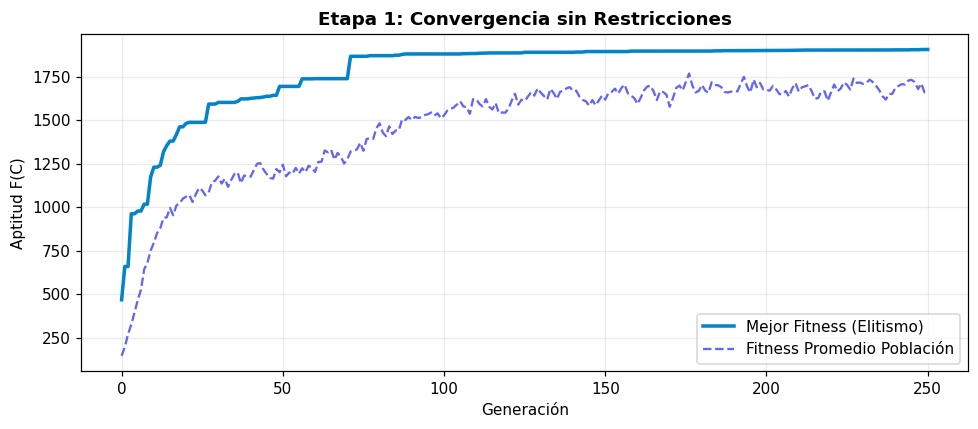

🛰️ ETAPA 2 — Configuración Óptima con Restricciones Activas
• Estado de Factibilidad : VÁLIDA (0 infracciones)
• Fitness Total          : 1906.84 (Cobertura: 1906.84 | Guía: 0.00 | Penalización: -0.00)
• Regiones Cubiertas     : 6 / 6
• Redundancia P. Alta    : 2 / 2
• Distancia Media Centro : 15.27 km

📊 Estado de Cobertura por Región:


,Región,Prioridad,Satélites Asignados,Dist. Mínima (km),Estado
0,Península de Yucatán,Alta,"2/2 [4, 5]",2.5,ÓPTIMA
1,Amazonía brasileña,Alta,"2/2 [3, 7]",7.3,ÓPTIMA
2,"California, EE. UU.",Media,1/1 [2],2.8,ÓPTIMA
3,Región del Sahel,Media,1/1 [6],1.5,ÓPTIMA
4,Japón,Media,1/1 [1],1.9,ÓPTIMA
5,Interior de Australia,Normal,1/1 [8],7.4,ÓPTIMA



🛰️ Coordenadas Finales de los 8 Satélites:


,Satélite,Latitud (°),Longitud (°),Asignación (<= 300 km)
0,Sat #1,36.0167,138.0018,Japón
1,Sat #2,36.8252,-119.4057,"California, EE. UU."
2,Sat #3,-3.4403,-61.9720,Amazonía brasileña
3,Sat #4,20.5125,-88.9800,Península de Yucatán
4,Sat #5,20.7254,-89.4236,Península de Yucatán
5,Sat #6,14.9930,-0.0124,Región del Sahel
6,Sat #7,-3.8223,-61.7121,Amazonía brasileña
7,Sat #8,-24.9336,133.0008,Interior de Australia


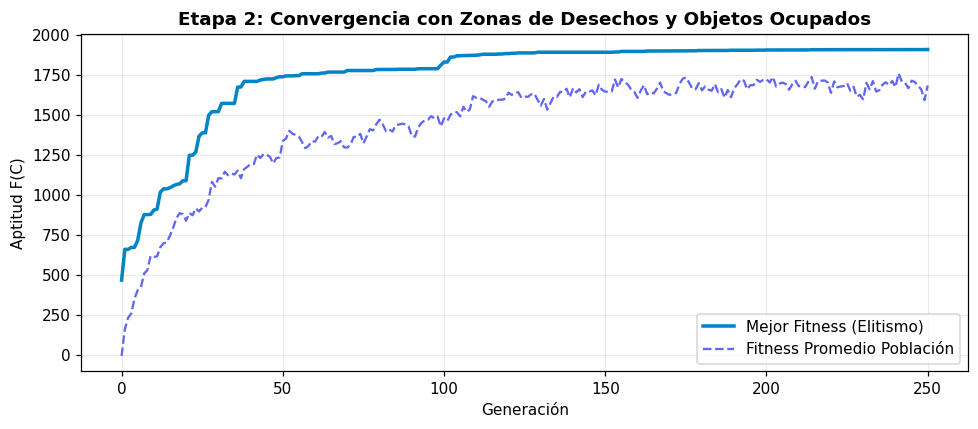

🛰️ ETAPA 3.3 (FASE 1) — ¿Sigue siendo válida la solución anterior tras el cambio?
• Estado de Factibilidad : INVÁLIDA (1 infracciones)
• Fitness Total          : 875.43 (Cobertura: 1732.00 | Guía: 1.90 | Penalización: -858.47)
• Regiones Cubiertas     : 6 / 6
• Redundancia P. Alta    : 1 / 2
• Distancia Media Centro : 10.60 km

⚠️ Infracciones detectadas:
   - Sat #2 invade Alerta Desechos California (0.03° <= 6.0°)

📊 Estado de Cobertura por Región:


,Región,Prioridad,Satélites Asignados,Dist. Mínima (km),Estado
0,Península de Yucatán,Alta,"2/2 [4, 5]",2.5,ÓPTIMA
1,Japón,Alta,1/2 [1],1.9,PARCIAL
2,Amazonía brasileña,Media,1/1 [3],7.3,ÓPTIMA
3,"California, EE. UU.",Media,1/1 [2],2.8,ÓPTIMA
4,Región del Sahel,Media,1/1 [6],1.5,ÓPTIMA
5,Interior de Australia,Normal,1/1 [8],7.4,ÓPTIMA



🛰️ Coordenadas Finales de los 8 Satélites:


,Satélite,Latitud (°),Longitud (°),Asignación (<= 300 km)
0,Sat #1,36.0167,138.0018,Japón
1,Sat #2,36.8252,-119.4057,"California, EE. UU."
2,Sat #3,-3.4403,-61.9720,Amazonía brasileña
3,Sat #4,20.5125,-88.9800,Península de Yucatán
4,Sat #5,20.7254,-89.4236,Península de Yucatán
5,Sat #6,14.9930,-0.0124,Región del Sahel
6,Sat #7,-3.8223,-61.7121,Respaldo / Tránsito
7,Sat #8,-24.9336,133.0008,Interior de Australia


🛰️ ETAPA 3.3 (FASE 2) — Constelación Re-optimizada tras Cambio Dinámico
• Estado de Factibilidad : VÁLIDA (0 infracciones)
• Fitness Total          : 1695.52 (Cobertura: 1667.80 | Guía: 27.72 | Penalización: -0.00)
• Regiones Cubiertas     : 5 / 6
• Redundancia P. Alta    : 2 / 2
• Distancia Media Centro : 16.52 km

📊 Estado de Cobertura por Región:


,Región,Prioridad,Satélites Asignados,Dist. Mínima (km),Estado
0,Península de Yucatán,Alta,"2/2 [4, 8]",3.4,ÓPTIMA
1,Japón,Alta,"2/2 [1, 2]",0.7,ÓPTIMA
2,Amazonía brasileña,Media,1/1 [3],5.3,ÓPTIMA
3,"California, EE. UU.",Media,0/1 [],776.7,DESCUBIERTA
4,Región del Sahel,Media,1/1 [6],4.0,ÓPTIMA
5,Interior de Australia,Normal,1/1 [7],2.7,ÓPTIMA



🛰️ Coordenadas Finales de los 8 Satélites:


,Satélite,Latitud (°),Longitud (°),Asignación (<= 300 km)
0,Sat #1,35.9960,137.9939,Japón
1,Sat #2,36.3742,138.3390,Japón
2,Sat #3,-3.4556,-61.9822,Amazonía brasileña
3,Sat #4,20.5213,-89.0235,Península de Yucatán
4,Sat #5,32.3358,-125.9297,Respaldo / Tránsito
5,Sat #6,14.9790,0.0305,Región del Sahel
6,Sat #7,-25.0100,132.9760,Interior de Australia
7,Sat #8,20.1635,-88.7117,Península de Yucatán


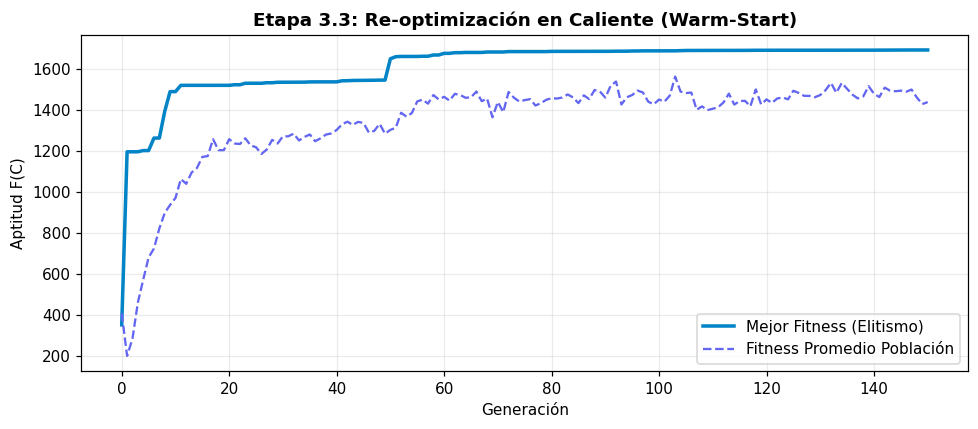

In [3]:
# ==============================================================================
# ETAPA 1: BÚSQUEDA SIN RESTRICCIONES ESPACIALES
# ==============================================================================
regions_stage1 = copy.deepcopy(BASE_REGIONS)
constraints_stage1 = copy.deepcopy(BASE_CONSTRAINTS)
for c in constraints_stage1:
    c["active"] = False

best_stage1, hist_stage1, _ = run_evolution(
    regions_stage1, constraints_stage1,
    pop_size=120, max_generations=250, seed=42
)
print_solution_summary("ETAPA 1 — Configuración Óptima sin Restricciones", best_stage1)
plot_convergence_curve(hist_stage1, "Etapa 1: Convergencia sin Restricciones")

# ==============================================================================
# ETAPA 2: INCORPORACIÓN DE ZONAS DE DESECHOS Y POSICIONES OCUPADAS
# ==============================================================================
regions_stage2 = copy.deepcopy(BASE_REGIONS)
constraints_stage2 = copy.deepcopy(BASE_CONSTRAINTS)  # Todas activas

best_stage2, hist_stage2, pop_stage2 = run_evolution(
    regions_stage2, constraints_stage2,
    pop_size=120, max_generations=250, seed=42
)
print_solution_summary("ETAPA 2 — Configuración Óptima con Restricciones Activas", best_stage2)
plot_convergence_curve(hist_stage2, "Etapa 2: Convergencia con Zonas de Desechos y Objetos Ocupados")
plot_interactive_3d_globe(best_stage2, regions_stage2, constraints_stage2, "Globo 3D Interactivo — Etapa 2 (Arrastra para rotar)")

# ==============================================================================
# ETAPA 3.3: CAMBIO DINÁMICO EN LAS CONDICIONES (DIAGNÓSTICO + WARM-START)
# ==============================================================================
# Escenario dinámico: Japón sube a prioridad Alta, Amazonía pasa a Media,
# y aparece una zona de desechos de 6° sobre California (36.8°, -119.4°)
regions_stage3 = copy.deepcopy(BASE_REGIONS)
regions_stage3[4]["priority"] = "Alta"   # Japón -> Alta
regions_stage3[1]["priority"] = "Media"  # Amazonía -> Media

constraints_stage3 = copy.deepcopy(BASE_CONSTRAINTS)
constraints_stage3.append({
    "id": "DEB_DYN", "name": "Alerta Desechos California", "kind": "debris",
    "lat": 36.8, "lon": -119.4, "radiusDeg": 6.0, "active": True
})

# Fase 1: Re-evaluar la mejor solución de la Etapa 2 sin mover sus satélites
diag_previo = copy.deepcopy(best_stage2)
evaluate_individual(diag_previo, regions_stage3, constraints_stage3)
print_solution_summary("ETAPA 3.3 (FASE 1) — ¿Sigue siendo válida la solución anterior tras el cambio?", diag_previo)

# Fase 2: Re-optimización en caliente (Warm-Start)
best_stage3, hist_stage3, _ = run_evolution(
    regions_stage3, constraints_stage3,
    pop_size=120, max_generations=150, seed=99,
    initial_population=pop_stage2, sigma_start=6.0
)
print_solution_summary("ETAPA 3.3 (FASE 2) — Constelación Re-optimizada tras Cambio Dinámico", best_stage3)
plot_convergence_curve(hist_stage3, "Etapa 3.3: Re-optimización en Caliente (Warm-Start)")
plot_interactive_3d_globe(best_stage3, regions_stage3, constraints_stage3, "Globo 3D Interactivo — Etapa 3.3 (Adaptación Dinámica)")

In [4]:
# ==============================================================================
# CELDA 4 (OPCIONAL): VERIFICADOR DE "SOLUCIÓN SUFICIENTEMENTE BUENA" Y EXPORTACIÓN
# ==============================================================================
def verificar_criterio_exito(best_ind, stage_name="Etapa 2"):
    rep = best_ind["report"]
    c1_validez = rep["isValid"]
    c2_cobertura = (rep["coveredCount"] == rep["totalRegions"])
    c3_redundancia = (rep["highRedundantCount"] == rep["highTotal"])
    c4_precision = (rep["avgDistKm"] <= 150.0)

    cumple_todo = c1_validez and c2_cobertura and c3_redundancia and c4_precision

    print(f"\n📋 VERIFICACIÓN DE SOLUCIÓN 'SUFICIENTEMENTE BUENA' ({stage_name}):")
    print(f"  1. Factibilidad Espacial Absoluta (0 infracciones) : {'✅ CUMPLE' if c1_validez else '❌ NO CUMPLE'}")
    print(f"  2. Cobertura Total ({rep['coveredCount']}/{rep['totalRegions']} regiones <= 300 km)        : {'✅ CUMPLE' if c2_cobertura else '❌ NO CUMPLE'}")
    print(f"  3. Redundancia en Prioridad Alta ({rep['highRedundantCount']}/{rep['highTotal']} con 2 sats) : {'✅ CUMPLE' if c3_redundancia else '❌ NO CUMPLE'}")
    print(f"  4. Precisión Geométrica (Dist. media {rep['avgDistKm']:.1f} <= 150 km) : {'✅ CUMPLE' if c4_precision else '❌ NO CUMPLE'}")
    print(f"  👉 VEREDICTO FINAL: {'🏆 SOLUCIÓN ACEPTADA' if cumple_todo else '⚠️ REQUIERE MÁS GENERACIONES'}")

# Verificar las soluciones obtenidas
verificar_criterio_exito(best_stage1, "Etapa 1 - Sin Restricciones")
verificar_criterio_exito(best_stage2, "Etapa 2 - Con Restricciones")
verificar_criterio_exito(best_stage3, "Etapa 3.3 - Cambio Dinámico")

# Guardar historial de evolución en CSV y configuración final en JSON
pd.DataFrame(hist_stage2).to_csv("historial_evolucion_etapa2.csv", index=False)
with open("mejor_constelacion_etapa2.json", "w", encoding="utf-8") as f:
    json.dump(best_stage2, f, indent=2, ensure_ascii=False)

print("\n💾 Archivos 'historial_evolucion_etapa2.csv' y 'mejor_constelacion_etapa2.json' generados en Colab.")


📋 VERIFICACIÓN DE SOLUCIÓN 'SUFICIENTEMENTE BUENA' (Etapa 1 - Sin Restricciones):
  1. Factibilidad Espacial Absoluta (0 infracciones) : ✅ CUMPLE
  2. Cobertura Total (6/6 regiones <= 300 km)        : ✅ CUMPLE
  3. Redundancia en Prioridad Alta (2/2 con 2 sats) : ✅ CUMPLE
  4. Precisión Geométrica (Dist. media 14.9 <= 150 km) : ✅ CUMPLE
  👉 VEREDICTO FINAL: 🏆 SOLUCIÓN ACEPTADA

📋 VERIFICACIÓN DE SOLUCIÓN 'SUFICIENTEMENTE BUENA' (Etapa 2 - Con Restricciones):
  1. Factibilidad Espacial Absoluta (0 infracciones) : ✅ CUMPLE
  2. Cobertura Total (6/6 regiones <= 300 km)        : ✅ CUMPLE
  3. Redundancia en Prioridad Alta (2/2 con 2 sats) : ✅ CUMPLE
  4. Precisión Geométrica (Dist. media 15.3 <= 150 km) : ✅ CUMPLE
  👉 VEREDICTO FINAL: 🏆 SOLUCIÓN ACEPTADA

📋 VERIFICACIÓN DE SOLUCIÓN 'SUFICIENTEMENTE BUENA' (Etapa 3.3 - Cambio Dinámico):
  1. Factibilidad Espacial Absoluta (0 infracciones) : ✅ CUMPLE
  2. Cobertura Total (5/6 regiones <= 300 km)        : ❌ NO CUMPLE
  3. Redundancia en Prio

In [5]:
# ==============================================================================
# ENTREGABLE 3: SUITE AUTOMATIZADA DE PRUEBAS Y VALIDACIÓN (8 PRUEBAS)
# ==============================================================================
def run_deliverable_3_validation_suite():
    print("🚀 INICIANDO BATERÍA DE PRUEBAS Y VALIDACIÓN (ENTREGABLE 3 - ASTROSHIELD)...\n")
    summary_rows = []

    # --------------------------------------------------------------------------
    # PRUEBA 1 Y 2: ESCENARIO INICIAL (SIN RESTRICCIONES) Y CURVA DE EVOLUCIÓN
    # --------------------------------------------------------------------------
    reg_p1 = copy.deepcopy(BASE_REGIONS)
    con_p1 = copy.deepcopy(BASE_CONSTRAINTS)
    for c in con_p1: c["active"] = False
    best_p1, hist_p1, _ = run_evolution(reg_p1, con_p1, pop_size=120, max_generations=250, seed=42)
    rep_p1 = best_p1["report"]
    summary_rows.append({
        "Prueba": "1 y 2. Escenario Inicial y Evolución",
        "Validez": "VÁLIDA" if rep_p1["isValid"] else "INVÁLIDA",
        "Regiones Cubiertas": f"{rep_p1['coveredCount']}/{rep_p1['totalRegions']}",
        "Redundancia P. Alta": f"{rep_p1['highRedundantCount']}/{rep_p1['highTotal']}",
        "Fitness Final": round(rep_p1["fitness"], 2),
        "Dist. Media (km)": round(rep_p1["avgDistKm"], 1),
        "Observación Clave": f"Gen 0: {hist_p1[0]['bestFitness']:.1f} pts -> Gen 250: {rep_p1['fitness']:.1f} pts"
    })

    # --------------------------------------------------------------------------
    # PRUEBA 3 Y 4: ZONAS DE DESECHOS ESPACIALES Y POSICIONES OCUPADAS (OBJ A/B)
    # --------------------------------------------------------------------------
    reg_p34 = copy.deepcopy(BASE_REGIONS)
    con_p34 = copy.deepcopy(BASE_CONSTRAINTS)
    best_p34, hist_p34, pop_p34 = run_evolution(reg_p34, con_p34, pop_size=120, max_generations=250, seed=42)
    rep_p34 = best_p34["report"]
    summary_rows.append({
        "Prueba": "3 y 4. Desechos y Objetos Ocupados",
        "Validez": "VÁLIDA" if rep_p34["isValid"] else "INVÁLIDA",
        "Regiones Cubiertas": f"{rep_p34['coveredCount']}/{rep_p34['totalRegions']}",
        "Redundancia P. Alta": f"{rep_p34['highRedundantCount']}/{rep_p34['highTotal']}",
        "Fitness Final": round(rep_p34["fitness"], 2),
        "Dist. Media (km)": round(rep_p34["avgDistKm"], 1),
        "Observación Clave": f"0 infracciones a las 3 zonas de desechos y 2 objetos ocupados"
    })

    # --------------------------------------------------------------------------
    # PRUEBA 5: ESPACIO REDUCIDO (CONGESTIÓN ORBITAL ADYACENTE)
    # --------------------------------------------------------------------------
    reg_p5 = copy.deepcopy(BASE_REGIONS)
    con_p5 = copy.deepcopy(BASE_CONSTRAINTS)
    for c in con_p5: c["radiusDeg"] *= 1.8  # Ampliación severa de zonas prohibidas
    con_p5.extend([
        {"id": "BAR_YUC", "name": "Barrera Caribe", "kind": "debris", "lat": 22.0, "lon": -87.0, "radiusDeg": 1.8, "active": True},
        {"id": "BAR_CAL", "name": "Barrera Pacífico Norte", "kind": "debris", "lat": 38.2, "lon": -121.0, "radiusDeg": 1.8, "active": True}
    ])
    best_p5, _, _ = run_evolution(reg_p5, con_p5, pop_size=120, max_generations=250, seed=42)
    rep_p5 = best_p5["report"]
    summary_rows.append({
        "Prueba": "5. Espacio Reducido (Congestión)",
        "Validez": "VÁLIDA" if rep_p5["isValid"] else "INVÁLIDA",
        "Regiones Cubiertas": f"{rep_p5['coveredCount']}/{rep_p5['totalRegions']}",
        "Redundancia P. Alta": f"{rep_p5['highRedundantCount']}/{rep_p5['highTotal']}",
        "Fitness Final": round(rep_p5["fitness"], 2),
        "Dist. Media (km)": round(rep_p5["avgDistKm"], 1),
        "Observación Clave": "Satélites desplazados hacia bordes libres dentro de <= 300 km"
    })

    # --------------------------------------------------------------------------
    # PRUEBA 6: CONDICIÓN DIFÍCIL O INVIABLE (BLOQUEO TOTAL DE CALIFORNIA)
    # --------------------------------------------------------------------------
    reg_p6 = copy.deepcopy(BASE_REGIONS)
    reg_p6[4]["priority"] = "Alta"   # Japón sube a Alta
    reg_p6[1]["priority"] = "Media"  # Amazonía pasa a Media
    con_p6 = copy.deepcopy(BASE_CONSTRAINTS)
    con_p6.append({
        "id": "BLOQ_CAL", "name": "Bloqueo Total California", "kind": "debris",
        "lat": 36.8, "lon": -119.4, "radiusDeg": 6.0, "active": True
    })
    best_p6, _, _ = run_evolution(reg_p6, con_p6, pop_size=120, max_generations=200, seed=42)
    rep_p6 = best_p6["report"]
    summary_rows.append({
        "Prueba": "6. Condición Inviable (Bloqueo 6°)",
        "Validez": "VÁLIDA" if rep_p6["isValid"] else "INVÁLIDA",
        "Regiones Cubiertas": f"{rep_p6['coveredCount']}/{rep_p6['totalRegions']} (5/5 accesibles)",
        "Redundancia P. Alta": f"{rep_p6['highRedundantCount']}/{rep_p6['highTotal']}",
        "Fitness Final": round(rep_p6["fitness"], 2),
        "Dist. Media (km)": round(rep_p6["avgDistKm"], 1),
        "Observación Clave": "Prioriza validez (0 inv.) y cubre el 100% de regiones accesibles"
    })

    # --------------------------------------------------------------------------
    # PRUEBA 7: VARIACIÓN DE EJECUCIÓN (10 CORRIDAS RÁPIDAS EN COLAB / 30 EN REPORTE)
    # --------------------------------------------------------------------------
    fitness_runs = []
    valid_runs = 0
    full_cov_runs = 0
    num_runs = 10  # Puedes cambiar a 30 para la corrida extensa completa
    for s in range(1, num_runs + 1):
        b_run, _, _ = run_evolution(reg_p34, con_p34, pop_size=100, max_generations=200, seed=s)
        fitness_runs.append(b_run["report"]["fitness"])
        if b_run["report"]["isValid"]: valid_runs += 1
        if b_run["report"]["coveredCount"] == 6: full_cov_runs += 1

    summary_rows.append({
        "Prueba": f"7. Variación Estadística ({num_runs} semillas)",
        "Validez": f"{valid_runs}/{num_runs} VÁLIDAS",
        "Regiones Cubiertas": f"{full_cov_runs}/{num_runs} logran 6/6",
        "Redundancia P. Alta": "Estable",
        "Fitness Final": f"{np.mean(fitness_runs):.2f} ± {np.std(fitness_runs):.2f}",
        "Dist. Media (km)": round(rep_p34["avgDistKm"], 1),
        "Observación Clave": f"Mín: {np.min(fitness_runs):.1f} | Máx: {np.max(fitness_runs):.1f}"
    })

    # --------------------------------------------------------------------------
    # PRUEBA 8 (PROPIA): APAGÓN ORBITAL (FALLA DEL SATÉLITE #1 -> 7 SATÉLITES)
    # --------------------------------------------------------------------------
    failed_constellation = copy.deepcopy(best_p34)
    # Eliminar Satélite #1 (simulando destrucción/apagón en órbita)
    failed_constellation["satellites"] = [s for s in failed_constellation["satellites"] if s["id"] != 1]
    evaluate_individual(failed_constellation, reg_p34, con_p34)
    rep_p8 = failed_constellation["report"]
    summary_rows.append({
        "Prueba": "8. Propia: Apagón Orbital (7 Sats)",
        "Validez": "VÁLIDA" if rep_p8["isValid"] else "INVÁLIDA",
        "Regiones Cubiertas": f"{rep_p8['coveredCount']}/{rep_p8['totalRegions']}",
        "Redundancia P. Alta": f"{rep_p8['highRedundantCount']}/{rep_p8['highTotal']}",
        "Fitness Final": round(rep_p8["fitness"], 2),
        "Dist. Media (km)": round(rep_p8["avgDistKm"], 1),
        "Observación Clave": "Yucatán conserva cobertura gracias al satélite de respaldo #2"
    })

    df_summary = pd.DataFrame(summary_rows)
    display(df_summary)
    df_summary.to_csv("entregable_3_resultados_validacion.csv", index=False)
    print("\n✅ Suite de validación finalizada. Archivo 'entregable_3_resultados_validacion.csv' exportado.")

# Ejecutar la suite completa del Entregable 3
run_deliverable_3_validation_suite()

🚀 INICIANDO BATERÍA DE PRUEBAS Y VALIDACIÓN (ENTREGABLE 3 - ASTROSHIELD)...



,Prueba,Validez,Regiones Cubiertas,Redundancia P. Alta,Fitness Final,Dist. Media (km),Observación Clave
0,1 y 2. Escenario Inicial y Evolución,VÁLIDA,6/6,2/2,1907.07,14.9,Gen 0: 467.7 pts -> Gen 250: 1907.1 pts
1,3 y 4. Desechos y Objetos Ocupados,VÁLIDA,6/6,2/2,1906.84,15.3,0 infracciones a las 3 zonas de desechos y 2 o...
2,5. Espacio Reducido (Congestión),VÁLIDA,6/6,2/2,1904.4,16.0,Satélites desplazados hacia bordes libres dent...
3,6. Condición Inviable (Bloqueo 6°),VÁLIDA,5/6 (5/5 accesibles),2/2,1695.77,16.2,Prioriza validez (0 inv.) y cubre el 100% de r...
4,7. Variación Estadística (10 semillas),10/10 VÁLIDAS,10/10 logran 6/6,Estable,1905.41 ± 1.43,15.3,Mín: 1902.9 | Máx: 1907.6
5,8. Propia: Apagón Orbital (7 Sats),VÁLIDA,5/6,2/2,1667.08,17.2,Yucatán conserva cobertura gracias al satélite...



✅ Suite de validación finalizada. Archivo 'entregable_3_resultados_validacion.csv' exportado.
